# NN_L3_holdout_noise

**Distribution of the test AUC of logistic regression on German credit over 200 random stratified 70/30 hold-out splits: how noisy a single split is on small data.**

Neural Networks and Deep Learning (NN), Lecture 3 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L3/NN_L3_holdout_noise/NN_L3_holdout_noise.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Lecture 3 of *Neural Networks and Deep Learning*: the chart `holdout_noise` of the slides, recomputed from the public data. Numbers printed with `show()` are the ones on the slide.

lowest AUC = 0.702   [holdout.min]
highest AUC = 0.842   [holdout.max]
standard deviation = 0.024   [holdout.sd]


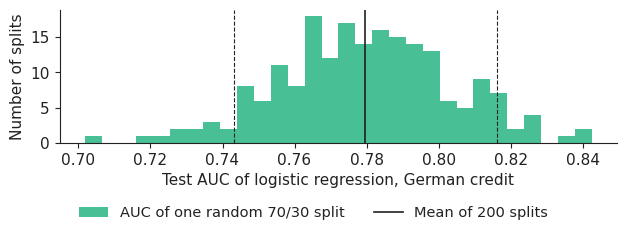

In [3]:
import xgboost as xgb            # import before torch (OpenMP runtimes on macOS)
import torch, torch.nn as nn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import StratifiedKFold, train_test_split
torch.set_num_threads(1)
SEED = 20261108

class Net(nn.Module):
    def __init__(self, d, hidden=(128, 128), p=0.0, bn=False):
        super().__init__()
        layers, k = [], d
        for h in hidden:
            layers.append(nn.Linear(k, h))
            if bn:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            if p > 0:
                layers.append(nn.Dropout(p))
            k = h
        layers.append(nn.Linear(k, 1)); self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

def fit(Xtr, ytr, Xva, yva, hidden=(128, 128), p=0.0, bn=False, wd=0.0, lr=1e-3, epochs=200, bs=128, seed=0,
        early=True, patience=20, loss='bce', opt_name='adam', record=False):
    """AdamW (decoupled weight decay) or SGD with momentum; dropout, batch norm, early stopping on the validation loss"""
    torch.manual_seed(SEED + seed); rng = np.random.default_rng(SEED + seed)
    m = Net(Xtr.shape[1], hidden, p, bn)
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=wd) if opt_name == 'adam' else torch.optim.SGD(m.parameters(), lr=lr, momentum=0.9, weight_decay=wd)
    lf = nn.BCEWithLogitsLoss() if loss == 'bce' else nn.MSELoss()
    Xt, yt = torch.tensor(Xtr), torch.tensor(ytr, dtype=torch.float32).view(-1, 1)
    Xv, yv = torch.tensor(Xva), torch.tensor(yva, dtype=torch.float32).view(-1, 1)
    best, state, bad, hist, best_ep = np.inf, None, 0, [], 0
    for ep in range(epochs):
        m.train(); idx = rng.permutation(len(Xt))
        for i in range(0, len(idx), bs):
            b = idx[i:i + bs]
            if len(b) < 2 and bn:
                continue
            opt.zero_grad(); lf(m(Xt[b]), yt[b]).backward(); opt.step()
        m.eval()
        with torch.no_grad():
            vl = float(lf(m(Xv), yv)); tl = float(lf(m(Xt), yt)) if record else np.nan
        hist.append((tl, vl))
        if not np.isfinite(vl):
            break
        if vl < best - 1e-5:
            best, bad, best_ep = vl, 0, ep + 1; state = {k: v.clone() for k, v in m.state_dict().items()}
        else:
            bad += 1
            if early and bad >= patience:
                break
    if early and state is not None:
        m.load_state_dict(state)
    m.eval()
    return m, hist, best_ep

def proba(m, X):
    with torch.no_grad():
        return torch.sigmoid(m(torch.tensor(X))).numpy().ravel()

g = pd.read_csv(DATA + 'german_credit.csv'); yg = g['default'].values.astype(int); Xg_raw = g.drop(columns='default')
def encode_german(tr, others):
    cat = [c for c in tr.columns if tr[c].dtype == object]; num = [c for c in tr.columns if c not in cat]
    levels = {c: sorted(tr[c].unique()) for c in cat}
    def f(d):
        x = d[num].astype(float).copy()
        for c in cat:
            for lv in levels[c][1:]:
                x[f'{c}_{lv}'] = (d[c] == lv).astype(float)
        return x
    xtr = f(tr); mu, sd = xtr.mean(), xtr.std().replace(0, 1)
    return [((xtr - mu) / sd).values.astype(np.float32)] + [((f(o) - mu) / sd).values.astype(np.float32) for o in others]
gi = np.arange(len(g))
g_tr, g_te = train_test_split(gi, test_size=0.2, stratify=yg, random_state=SEED)
g_tr, g_va = train_test_split(g_tr, test_size=0.25, stratify=yg[g_tr], random_state=SEED)
Gtr, Gva, Gte = encode_german(Xg_raw.iloc[g_tr], [Xg_raw.iloc[g_va], Xg_raw.iloc[g_te]])
aucs = []
for s in range(200):
    a, b = train_test_split(np.arange(len(yg)), test_size=0.3, stratify=yg, random_state=SEED + s); xa, xb = encode_german(Xg_raw.iloc[a], [Xg_raw.iloc[b]])
    aucs.append(roc_auc_score(yg[b], LogisticRegression(C=1.0, max_iter=5000).fit(xa, yg[a]).predict_proba(xb)[:, 1]))
aucs = np.array(aucs)
show('holdout.min', 'lowest AUC', round(float(aucs.min()), 3)); show('holdout.max', 'highest AUC', round(float(aucs.max()), 3)); show('holdout.sd', 'standard deviation', round(float(aucs.std(ddof=1)), 3))
fig, ax = plt.subplots(figsize=(6.4, 2.4))
ax.hist(aucs, bins=30, color=PAL['benchmark'], alpha=0.8, label='AUC of one random 70/30 split'); ax.axvline(aucs.mean(), color='#222222', lw=1.2, label='Mean of 200 splits')
for q in np.percentile(aucs, [5, 95]):
    ax.axvline(q, color='#222222', lw=0.8, ls='--')
ax.set_xlabel('Test AUC of logistic regression, German credit'); ax.set_ylabel('Number of splits')
legend_bottom(fig, ncol=2); fig.tight_layout(rect=(0, 0.12, 1, 1))
fig.savefig('holdout_noise.png', dpi=200, transparent=True, bbox_inches='tight'); plt.show()